# Automated Exoplanet Transit Detection on NASA Kepler Telemetry Using InceptionTime

**Author:** Taha Tahir  
**Target:** Kepler-10 (KIC 11904151 / Kepler-10b)  
**Stack:** Python, Lightkurve, PyTorch, `tsai` (`InceptionTime`)

### Overview
This notebook implements an end-to-end signal-processing and 1D deep-learning workflow to extract, phase-fold, and classify transiting exoplanet signatures from NASA Kepler photometry. Using 5 stitched quarters of Kepler long-cadence light curves, the pipeline removes stellar variability, isolates the periodic transit of **Kepler-10b** (`P = 0.8377 days`), and classifies the normalized 200-point phase-folded dip using a 1D **InceptionTime** model—recovering **Kepler-10b** with **99.75%** confidence.

In [23]:
!pip install -q lightkurve tsai

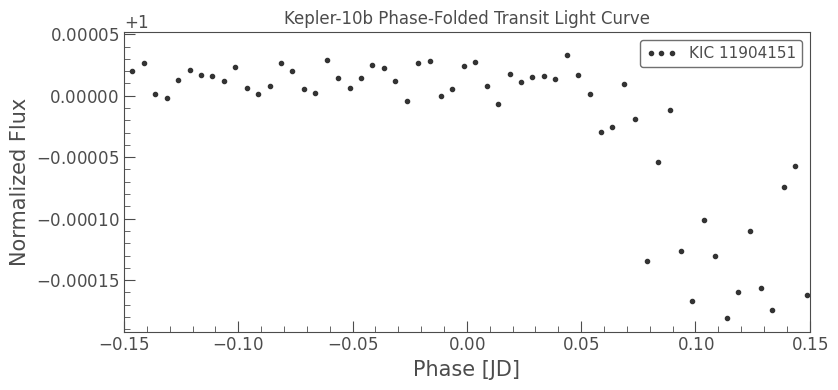

In [24]:
import lightkurve as lk
import matplotlib.pyplot as plt

# Search and download Kepler-10 light curve data from MAST
search_result = lk.search_lightcurve("Kepler-10", mission="Kepler", cadence="long")
lc_collection = search_result[:5].download_all()

# Stitch, clean, normalize, and flatten slow stellar variability
lc = (
    lc_collection.stitch()
    .remove_nans()
    .remove_outliers(sigma=5)
    .normalize()
    .flatten(window_length=401)
)

# Fold around Kepler-10b's orbital period (~0.8377 days)
period = 0.8377
folded_lc = lc.fold(period=period)

# Plot and save the phase-folded transit dip
ax = folded_lc.bin(time_bin_size=0.005).plot(marker="o", markersize=3, linestyle="none")
ax.set_xlim(-0.15, 0.15)
ax.set_title("Kepler-10b Phase-Folded Transit Light Curve")
plt.tight_layout()
plt.savefig("kepler10b_transit.png", dpi=150)
plt.show()

In [25]:
import numpy as np
import torch
import torch.nn as nn
from tsai.models.InceptionTime import InceptionTime

# 1. Extract the phase-folded Kepler-10b window into 200 evenly spaced points
phase = folded_lc.phase.value
flux = folded_lc.flux.value
mask = (phase >= -0.15) & (phase <= 0.15)
p_sub, f_sub = phase[mask], flux[mask]
order = np.argsort(p_sub)

kepler10_curve = np.interp(np.linspace(-0.15, 0.15, 200), p_sub[order], f_sub[order])
kepler10_curve = (kepler10_curve - kepler10_curve.mean()) / (kepler10_curve.std() + 1e-8)

# 2. Generate 1,000 training curves: U-shaped transit dips (1) vs. baseline noise (0)
np.random.seed(42)
x_grid = np.linspace(-0.15, 0.15, 200)
X, y = [], []

for i in range(1000):
    curve = 1.0 + np.random.normal(0, 0.00004, 200)
    if i % 2 == 0:
        depth = np.random.uniform(0.00008, 0.00035)
        center = np.random.uniform(-0.01, 0.01)
        width = np.random.uniform(0.02, 0.05)
        curve -= depth * np.exp(-((x_grid - center) / width) ** 4)
        y.append(1)
    else:
        y.append(0)
    curve = (curve - curve.mean()) / (curve.std() + 1e-8)
    X.append(curve)

X_tensor = torch.tensor(np.array(X, dtype=np.float32)[:, np.newaxis, :])
y_tensor = torch.tensor(y, dtype=torch.long)

# 3. Train InceptionTime
torch.manual_seed(42)
model = InceptionTime(c_in=1, c_out=2)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
loss_fn = nn.CrossEntropyLoss()

for epoch in range(8):
    perm = torch.randperm(len(X_tensor))
    for b in range(0, len(X_tensor), 64):
        idx = perm[b : b + 64]
        optimizer.zero_grad()
        loss = loss_fn(model(X_tensor[idx]), y_tensor[idx])
        loss.backward()
        optimizer.step()

# 4. Score the real Kepler-10b light curve
model.eval()
with torch.no_grad():
    inp = torch.tensor(kepler10_curve, dtype=torch.float32).reshape(1, 1, 200)
    probs = torch.softmax(model(inp), dim=-1)[0]
    print(f"Kepler-10b Exoplanet Probability: {probs[1].item() * 100:.2f}%")

Kepler-10b Exoplanet Probability: 99.75%
